# Домашнее задание 2.3: Связанные колебания (🟢)

Две одинаковые массы $m$, каждая пружиной жёсткости $k_0$ прикреплена к неподвижной опоре;
между массами — пружина жёсткости $k_c$ и демпфер $c$:

$$m\ddot x_1 = -k_0x_1 - k_c(x_1-x_2) - c(\dot x_1-\dot x_2),\qquad
m\ddot x_2 = -k_0x_2 - k_c(x_2-x_1) - c(\dot x_2-\dot x_1)$$

На зелёном уровне связь слабая, $k_c \ll k_0$, демпфера нет, $c = 0$. Сдвигаю первую массу и
отпускаю обе без начальной скорости. Методы — RK4 и скоростной метод Верле.

Что нужно построить: смещения обеих масс (биения), кинетическую энергию каждой массы и полную
механическую энергию системы.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 1. Параметры, собственные частоты, точное решение

Параметры: $m = 1$, $k_0 = 1$, $k_c = 0.05$, $c = 0$. Начальные условия: $x_1 = 1$, $x_2 = 0$,
$\dot x_1 = \dot x_2 = 0$.

В нормальных координатах $q_\pm = (x_1 \pm x_2)/2$ система распадается на два независимых
осциллятора:

| мода | как движутся массы | собственная частота |
|---|---|---|
| синфазная, $q_+$ | $x_1 = x_2$, средняя пружина не растянута | $\omega_1 = \sqrt{k_0/m}$ |
| противофазная, $q_-$ | $x_1 = -x_2$ | $\omega_2 = \sqrt{(k_0 + 2k_c)/m}$ |

Точное решение при этих начальных условиях:

$$x_1 = \tfrac12(\cos\omega_1 t + \cos\omega_2 t) = \cos\tfrac{(\omega_2-\omega_1)t}{2}\,\cos\tfrac{(\omega_1+\omega_2)t}{2},\qquad
x_2 = \tfrac12(\cos\omega_1 t - \cos\omega_2 t) = \sin\tfrac{(\omega_2-\omega_1)t}{2}\,\sin\tfrac{(\omega_1+\omega_2)t}{2}$$

Энергия целиком перетекает от первой массы ко второй и обратно. Период биений — время между
соседними минимумами огибающей одной массы: $T_b = 2\pi/(\omega_2 - \omega_1)$.

In [2]:
m, k0, kc, c = 1.0, 1.0, 0.05, 0.0
w1 = np.sqrt(k0 / m)
w2 = np.sqrt((k0 + 2 * kc) / m)
T_beat = 2 * np.pi / (w2 - w1)
print(f"omega_1 = {w1:.6f}, omega_2 = {w2:.6f}, период биений T_b = {T_beat:.3f}")


def exact(t):
    return 0.5 * (np.cos(w1 * t) + np.cos(w2 * t)), 0.5 * (np.cos(w1 * t) - np.cos(w2 * t))


def accel(x, v):
    x1, x2 = x
    v1, v2 = v
    a1 = (-k0 * x1 - kc * (x1 - x2) - c * (v1 - v2)) / m
    a2 = (-k0 * x2 - kc * (x2 - x1) - c * (v2 - v1)) / m
    return np.array([a1, a2])


def kinetic(V):
    return 0.5 * m * V**2


def total_energy(X, V):
    return (0.5 * m * (V**2).sum(-1) + 0.5 * k0 * (X**2).sum(-1)
            + 0.5 * kc * (X[..., 0] - X[..., 1])**2)

omega_1 = 1.000000, omega_2 = 1.048809, период биений T_b = 128.730


## 2. Методы

RK4 работает с системой $(x, v)$. Скоростной метод Верле:
$v_{n+1/2} = v_n + \tfrac{dt}{2}a_n$, $x_{n+1} = x_n + dt\,v_{n+1/2}$,
$v_{n+1} = v_{n+1/2} + \tfrac{dt}{2}a_{n+1}$. При $c = 0$ ускорение от скорости не зависит,
так что подходит обычная явная форма метода.

In [3]:
x_init = np.array([1.0, 0.0])
v_init = np.array([0.0, 0.0])


def solve_rk4(dt, t_end):
    n = int(round(t_end / dt))
    X = np.empty((n + 1, 2)); V = np.empty((n + 1, 2))
    x, v = x_init.copy(), v_init.copy()
    X[0], V[0] = x, v
    for i in range(n):
        k1x, k1v = v, accel(x, v)
        k2x, k2v = v + dt / 2 * k1v, accel(x + dt / 2 * k1x, v + dt / 2 * k1v)
        k3x, k3v = v + dt / 2 * k2v, accel(x + dt / 2 * k2x, v + dt / 2 * k2v)
        k4x, k4v = v + dt * k3v, accel(x + dt * k3x, v + dt * k3v)
        x = x + dt / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        v = v + dt / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
        X[i + 1], V[i + 1] = x, v
    return np.arange(n + 1) * dt, X, V


def solve_verlet(dt, t_end):
    n = int(round(t_end / dt))
    X = np.empty((n + 1, 2)); V = np.empty((n + 1, 2))
    x, v = x_init.copy(), v_init.copy()
    X[0], V[0] = x, v
    a = accel(x, v)
    for i in range(n):
        vh = v + dt / 2 * a
        x = x + dt * vh
        a = accel(x, vh)
        v = vh + dt / 2 * a
        X[i + 1], V[i + 1] = x, v
    return np.arange(n + 1) * dt, X, V

## 3. Расчёт для нескольких шагов

Интервал $0 \le t \le 400$ — около трёх периодов биений. Шаги $dt \in \{0.5, 0.2, 0.1, 0.05\}$;
период быстрых колебаний $2\pi/\omega_1 \approx 6.28$.

In [4]:
t_end = 400.0
dts = [0.5, 0.2, 0.1, 0.05]
solvers = {"RK4": solve_rk4, "Верле": solve_verlet}
runs = {(name, dt): solvers[name](dt, t_end) for name in solvers for dt in dts}
E0 = total_energy(x_init, v_init)

print(f"{'метод':>6} {'dt':>5} {'max|x1 - x1_exact|':>20} {'max|ΔE|/E0':>12}")
for (name, dt), (t, X, V) in runs.items():
    e = np.max(np.abs(X[:, 0] - exact(t)[0]))
    eE = np.max(np.abs(total_energy(X, V) - E0)) / E0
    print(f"{name:>6} {dt:5.2f} {e:20.3e} {eE:12.3e}")

 метод    dt   max|x1 - x1_exact|   max|ΔE|/E0
   RK4  0.50            2.182e-01    1.785e-01
   RK4  0.20            5.868e-03    2.073e-03
   RK4  0.10            3.671e-04    6.510e-05
   RK4  0.05            2.295e-05    2.036e-06
 Верле  0.50            1.966e+00    6.570e-02
 Верле  0.20            6.834e-01    1.052e-02
 Верле  0.10            1.741e-01    2.630e-03
 Верле  0.05            4.355e-02    6.577e-04


## 4. Смещения масс: биения

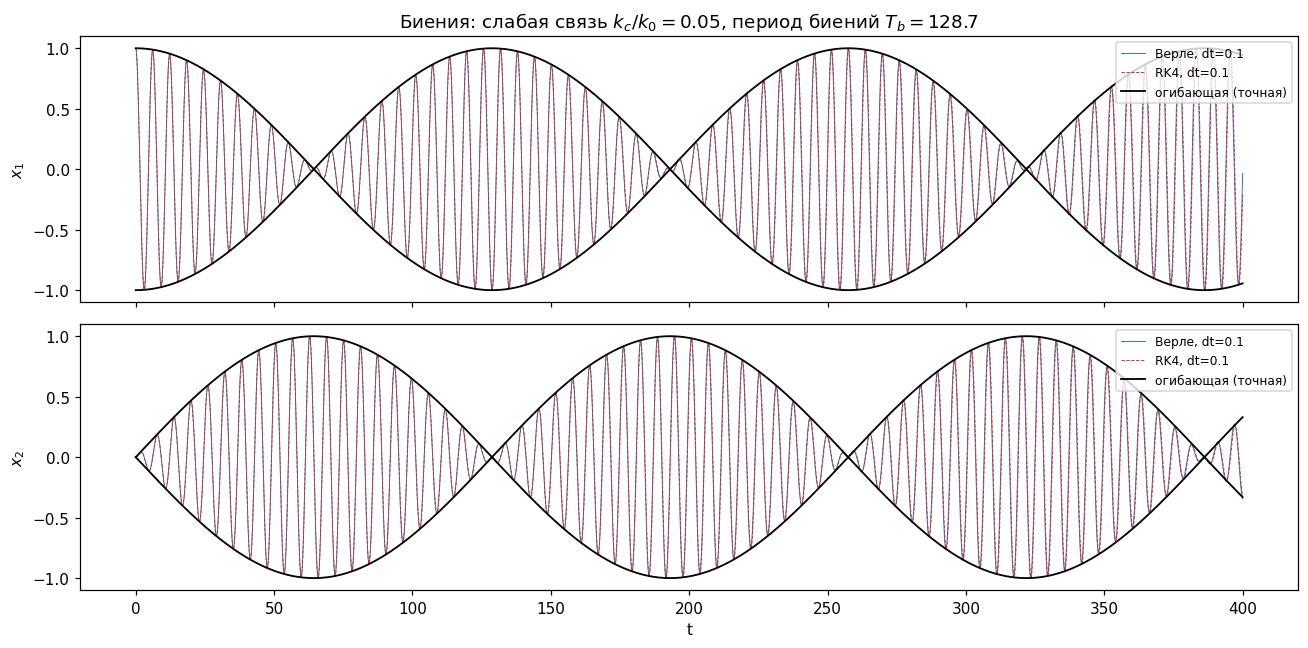

In [5]:
t_fine = np.linspace(0, t_end, 20001)
x1e, x2e = exact(t_fine)
env = np.abs(np.cos((w2 - w1) * t_fine / 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for k, ax in enumerate(axes):
    t, X, V = runs[("Верле", 0.1)]
    ax.plot(t, X[:, k], "C0-", lw=0.6, label="Верле, dt=0.1")
    t, X, V = runs[("RK4", 0.1)]
    ax.plot(t, X[:, k], "C3--", lw=0.6, label="RK4, dt=0.1")
    envk = env if k == 0 else np.sqrt(1 - env**2)
    ax.plot(t_fine, envk, "k-", lw=1.2, label="огибающая (точная)")
    ax.plot(t_fine, -envk, "k-", lw=1.2)
    ax.set_ylabel(f"$x_{k+1}$")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_title(f"Биения: слабая связь $k_c/k_0 = {kc/k0}$, период биений $T_b = {T_beat:.1f}$")
axes[1].set_xlabel("t")
fig.tight_layout()
plt.show()

Как влияет шаг: $x_1$ на последнем периоде биений при разных $dt$.

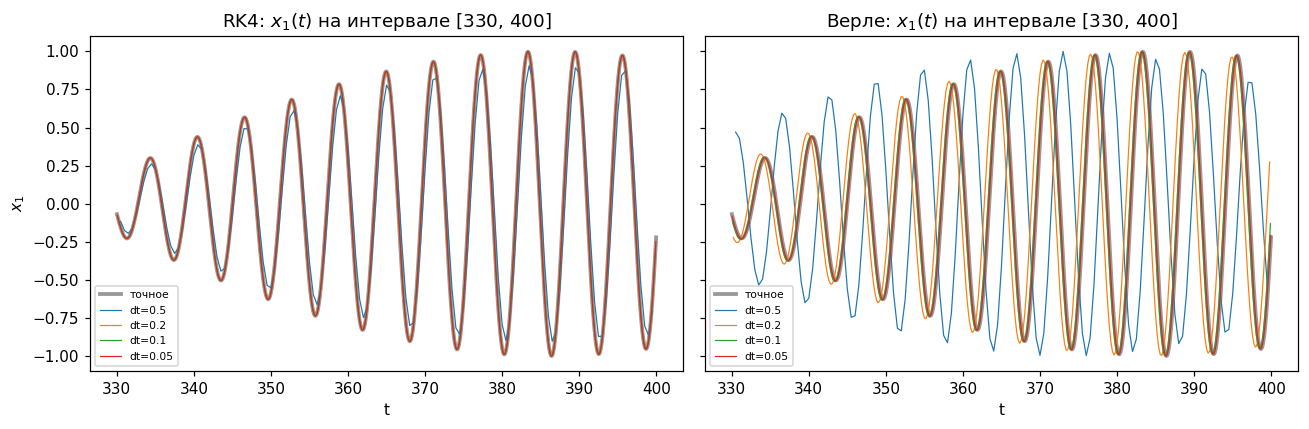

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
win = (t_fine > 330) & (t_fine < 400)
for ax, name in zip(axes, ["RK4", "Верле"]):
    ax.plot(t_fine[win], x1e[win], color="0.6", lw=2.5, label="точное")
    for dt in dts:
        t, X, V = runs[(name, dt)]
        sel = (t > 330) & (t < 400)
        ax.plot(t[sel], X[sel, 0], lw=0.8, label=f"dt={dt}")
    ax.set_title(f"{name}: $x_1(t)$ на интервале [330, 400]")
    ax.set_xlabel("t")
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("$x_1$")
fig.tight_layout()
plt.show()

## 5. Численные частоты и период биений

Частоту каждой моды считаю по нормальной координате $q_\pm$. Моменты, когда она проходит через
ноль, нахожу линейной интерполяцией между узлами; частота равна $\pi$, делённому на средний
интервал между соседними нулями.

Для гармонического осциллятора численная частота метода Верле известна точно:
$\tilde\omega = \frac{2}{dt}\arcsin\frac{\omega\,dt}{2}$. Амплитуду метод не меняет, а частоту
сдвигает на $\omega^3 dt^2/24$. У RK4 относительная ошибка частоты порядка $(\omega\,dt)^4$, и
вдобавок амплитуда медленно убывает.

In [7]:
def zero_cross_freq(t, q):
    s = np.sign(q)
    idx = np.where(s[:-1] * s[1:] < 0)[0]
    tz = t[idx] - q[idx] * (t[idx + 1] - t[idx]) / (q[idx + 1] - q[idx])
    return np.pi / np.mean(np.diff(tz))


rows = []
for (name, dt), (t, X, V) in runs.items():
    qp = 0.5 * (X[:, 0] + X[:, 1])
    qm = 0.5 * (X[:, 0] - X[:, 1])
    W1, W2 = zero_cross_freq(t, qp), zero_cross_freq(t, qm)
    rows.append((name, dt, W1, W2, 2 * np.pi / (W2 - W1)))

print(f"точные: omega_1 = {w1:.8f}, omega_2 = {w2:.8f}, T_b = {T_beat:.4f}\n")
print(f"{'метод':>6} {'dt':>5} {'omega_1':>11} {'отн.ош.':>10} {'omega_2':>11} {'отн.ош.':>10} "
      f"{'T_b':>9} {'отн.ош.':>10} {'Верле, теория':>14}")
for name, dt, W1, W2, Tb in rows:
    th = (2 / dt) * np.arcsin(w1 * dt / 2) if name == "Верле" else np.nan
    th_s = f"{th:14.8f}" if name == "Верле" else f"{'—':>14}"
    print(f"{name:>6} {dt:5.2f} {W1:11.8f} {(W1 - w1) / w1:10.2e} {W2:11.8f} {(W2 - w2) / w2:10.2e} "
          f"{Tb:9.4f} {(Tb - T_beat) / T_beat:10.2e} {th_s}")

точные: omega_1 = 1.00000000, omega_2 = 1.04880885, T_b = 128.7305

 метод    dt     omega_1    отн.ош.     omega_2    отн.ош.       T_b    отн.ош.  Верле, теория
   RK4  0.50  0.99952443  -4.76e-04  1.04820548  -5.75e-04  129.0684   2.63e-03              —
   RK4  0.20  0.99998634  -1.37e-05  1.04879213  -1.59e-05  128.7385   6.27e-05              —
   RK4  0.10  0.99999910  -9.00e-07  1.04880783  -9.73e-07  128.7308   2.47e-06              —
   RK4  0.05  0.99999995  -5.49e-08  1.04880878  -6.05e-08  128.7305   1.75e-07              —
 Верле  0.50  1.01073034   1.07e-02  1.06120743   1.18e-02  124.4760  -3.30e-02     1.01072102
 Верле  0.20  1.00167377   1.67e-03  1.05074166   1.84e-03  128.0509  -5.28e-03     1.00167421
 Верле  0.10  1.00041709   4.17e-04  1.04929013   4.59e-04  128.5614  -1.31e-03     1.00041714
 Верле  0.05  1.00010420   1.04e-04  1.04892906   1.15e-04  128.6882  -3.28e-04     1.00010420


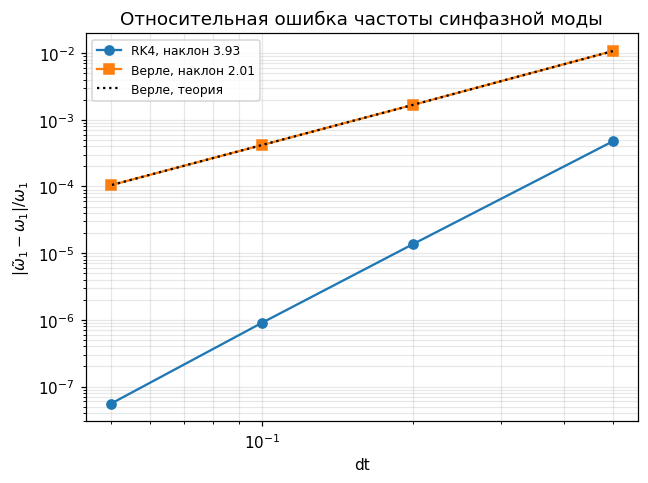

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, mk in [("RK4", "o-"), ("Верле", "s-")]:
    errs = [abs(W1 - w1) / w1 for n_, dt, W1, W2, Tb in rows if n_ == name]
    p = np.polyfit(np.log(dts), np.log(errs), 1)[0]
    ax.loglog(dts, errs, mk, label=f"{name}, наклон {p:.2f}")
dd = np.array(dts)
ax.loglog(dd, np.abs((2 / dd) * np.arcsin(w1 * dd / 2) - w1) / w1, "k:", label="Верле, теория")
ax.set_xlabel("dt"); ax.set_ylabel(r"$|\tilde\omega_1 - \omega_1|/\omega_1$")
ax.set_title("Относительная ошибка частоты синфазной моды")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Спектр $x_1$ (Верле, $dt = 0.05$, окно Ханна): два пика на собственных частотах.

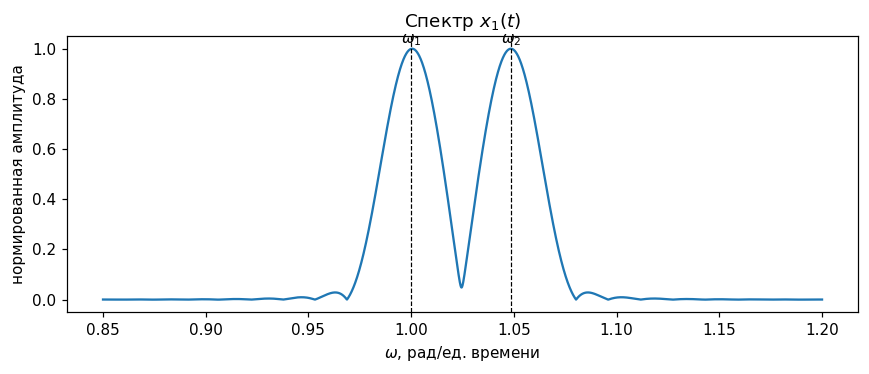

In [9]:
t, X, V = runs[("Верле", 0.05)]
sig = X[:, 0] * np.hanning(len(t))
nfft = 2**20
spec = np.abs(np.fft.rfft(sig, nfft))
freq = 2 * np.pi * np.fft.rfftfreq(nfft, d=0.05)
sel = (freq > 0.85) & (freq < 1.2)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(freq[sel], spec[sel] / spec[sel].max(), "C0-")
for w, lab in [(w1, r"$\omega_1$"), (w2, r"$\omega_2$")]:
    ax.axvline(w, color="k", ls="--", lw=0.8)
    ax.text(w, 1.02, lab, ha="center")
ax.set_xlabel(r"$\omega$, рад/ед. времени"); ax.set_ylabel("нормированная амплитуда")
ax.set_title("Спектр $x_1(t)$")
fig.tight_layout()
plt.show()

## 6. Энергия

Кинетическая энергия каждой массы $K_i = \tfrac12 m\dot x_i^2$ и полная механическая энергия
$E = K_1 + K_2 + \tfrac12k_0(x_1^2 + x_2^2) + \tfrac12k_c(x_1 - x_2)^2$.

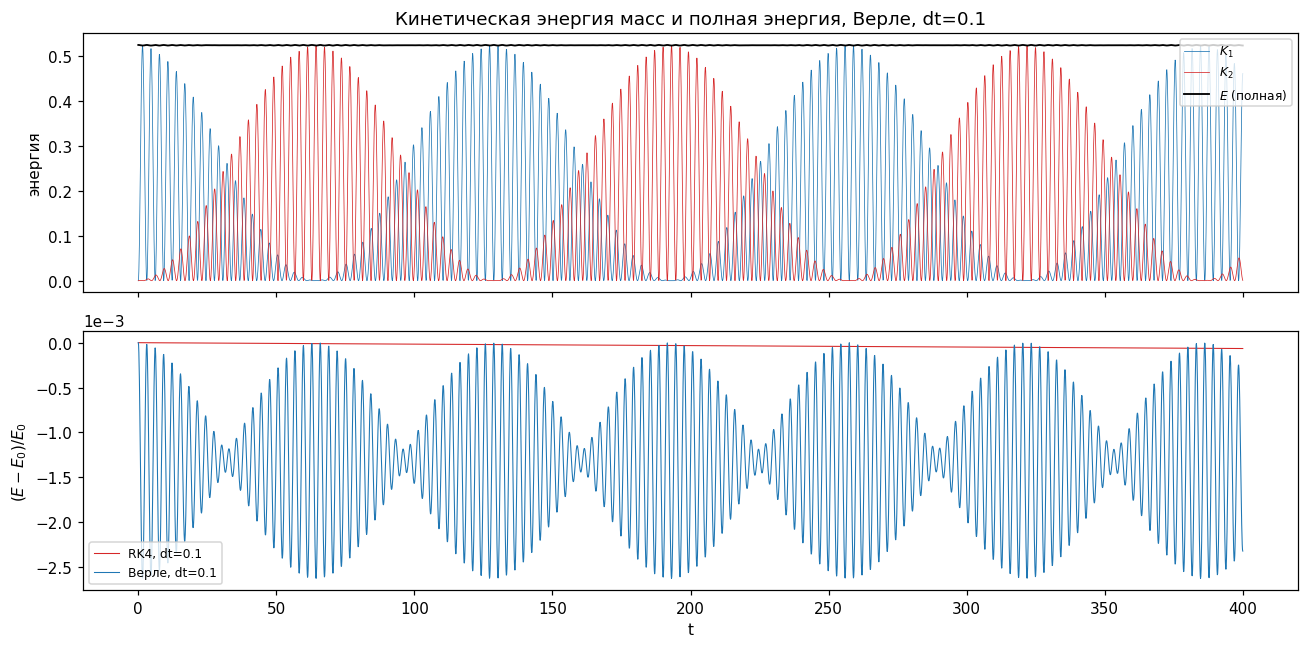

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t, X, V = runs[("Верле", 0.1)]
K = kinetic(V)
axes[0].plot(t, K[:, 0], "C0-", lw=0.5, label="$K_1$")
axes[0].plot(t, K[:, 1], "C3-", lw=0.5, label="$K_2$")
axes[0].plot(t, total_energy(X, V), "k-", lw=1.2, label="$E$ (полная)")
axes[0].set_ylabel("энергия")
axes[0].set_title("Кинетическая энергия масс и полная энергия, Верле, dt=0.1")
axes[0].legend(loc="upper right", fontsize=8)

for name, st in [("RK4", "C3-"), ("Верле", "C0-")]:
    t, X, V = runs[(name, 0.1)]
    axes[1].plot(t, (total_energy(X, V) - E0) / E0, st, lw=0.7, label=f"{name}, dt=0.1")
axes[1].set_ylabel("$(E - E_0)/E_0$")
axes[1].set_xlabel("t")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

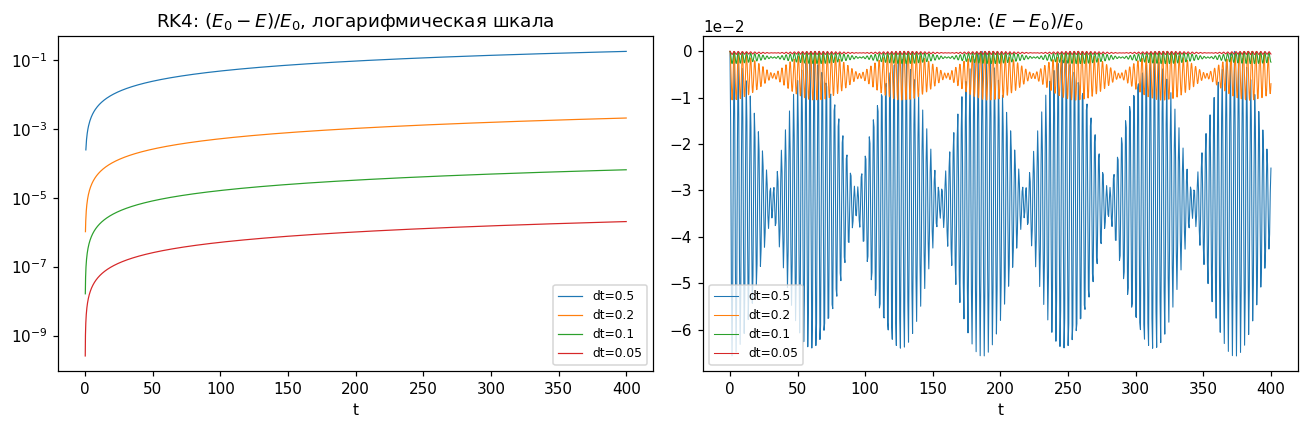

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for dt in dts:
    t, X, V = runs[("RK4", dt)]
    axes[0].semilogy(t[1:], (E0 - total_energy(X[1:], V[1:])) / E0, lw=0.8, label=f"dt={dt}")
    t, X, V = runs[("Верле", dt)]
    axes[1].plot(t, (total_energy(X, V) - E0) / E0, lw=0.7, label=f"dt={dt}")
axes[0].set_title("RK4: $(E_0 - E)/E_0$, логарифмическая шкала")
axes[1].set_title("Верле: $(E - E_0)/E_0$")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes:
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Результаты

1. При слабой связи ($k_c/k_0 = 0.05$) хорошо видны биения: энергия колебаний целиком
   переходит от первой массы ко второй и обратно с периодом $T_b = 2\pi/(\omega_2-\omega_1)
   \approx 128.7$. При $dt = 0.1$ огибающие численных решений совпадают с точными
   $|\cos\frac{(\omega_2-\omega_1)t}{2}|$ и $|\sin\frac{(\omega_2-\omega_1)t}{2}|$.
2. В спектре $x_1(t)$ два пика — на $\omega_1 = 1$ и на $\omega_2 = \sqrt{1.1} \approx 1.0488$.
   Биения получаются от наложения двух нормальных мод с близкими частотами.
3. Метод Верле завышает частоты на $\omega^3dt^2/24$, и численные значения совпадают с
   формулой $\frac{2}{dt}\arcsin\frac{\omega dt}{2}$ до 7–8 значащих цифр. У RK4 ошибка частоты
   растёт как $dt^4$: при $dt = 0.1$ это $10^{-6}$, у Верле — $4\cdot10^{-4}$.
4. Период биений зависит от разности двух близких частот, поэтому его относительная ошибка
   больше, чем у каждой частоты. У Верле при $dt = 0.5$ частоты ошибаются примерно на 1%, а
   $T_b$ — на 3.3%. Сдвиг частоты растёт как $\omega^3$, так что $\omega_2$ уезжает сильнее
   $\omega_1$, и численная разность частот выходит на 3.4% больше точной.
5. Ошибка по $x_1$ набегает в основном из-за фазы. У Верле при $dt = 0.1$ на интервале 400 она
   доходит до $0.17$ и убывает как $dt^2$, у RK4 — $4\cdot10^{-4}$ и убывает как $dt^4$.
6. У RK4 полная энергия монотонно убывает: метод вносит численную диссипацию, ошибка растёт
   как $dt^5$, при $dt = 0.5$ к $t = 400$ теряется 18% энергии. У Верле энергия не дрейфует:
   отклонение ограничено, порядка $(\omega dt)^2/4$, и модулировано с периодом биений. На
   длинном интервале Верле держит амплитуду биений при любом из проверенных шагов, RK4 с
   крупным шагом — нет.